# ♟️ Chess Numba — 新舊引擎錦標賽對戰 (Colab Tournament Runner)

本 Notebook 用於在 Google Colab 雲端高並行 CPU 環境下，讓 **新版本引擎 (Candidate / New)** 與 **基準版本引擎 (Baseline / Old)** 進行成對換先（Color-swapped Pairs）錦標賽對抗：

### 🎯 本輪對抗設定 (實驗 C：解耦 Correction History 的 static_score 與 corrected_eval)
* **Engine 1 (New / Candidate)**: chess_engine/classical
  * ✅ **Stage 1 零樹變動加速與正交解耦（0-node delta）**：
    MovePicker 與 QSearch 的 SEE O(1) 快速短路與棋子型別重用、check_sq 位元棋盤重用、Step 14d 前置合法性檢查、Fail-Low 緩衝區邊界修復、Killer2 動態內插與歷史懲罰 Scale/Decay 完全解耦。
  * ✅ **實驗 C（解耦 Correction History 修正量計算，對齊 Stockfish 19 Step 20）**：
    在節點搜尋結束更新 Correction History（Pawn, Minor, Non-Pawn, Continuation）時，將偏差計算由原本被置換表覆蓋的 max_eval - static_score 改為使用純粹評估修正分數 max_eval - corrected_eval。
    過去當 TT 命中時，static_score 經常被 TT 評估邊界覆蓋，導致 max_eval - static_score 經常為 0，嚴重閹割了 Correction History 在關鍵分支的持續學習能力；解耦後修正歷史能在 TT 命中時依然維持完整的評估梯度學習，同時搜尋剪枝與 LMR 仍繼續保留高置信度的 TT 精煉靜態評估。
* **Engine 2 (Old / Baseline)**: chess_engine/classical_old（E76 生產基準：RFP beta 權重 412）
* **時控模式**: 固定節點（400,000 nodes 長時控）
* **對戰規格**: 600 局（300 對開局交換白黑），64MB 轉置表，開局庫 data/openings.epd
* **統計模型**: SPRT（Sequential Probability Ratio Test）與 Elo 95% 置信區間


In [1]:
# =====================================================================
# 步驟 1: 檢視 Colab 雲端硬體規格與 CPU 核心數
# =====================================================================
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.3Gi        47Gi       2.2Mi       3.2Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.16


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
# =====================================================================
# 步驟 2: 載入代碼庫與相依套件
# 支援方式 A：直接從 GitHub 倉庫拉取最新分支
# 支援方式 B：若您上傳了 zip 或放在 Google Drive，亦可解壓至 /content/chess_numba
# =====================================================================
import os

repo_url = "https://github.com/b08203031/chess_numba.git"
branch = "feat-initial-bitboard-setup"

if not os.path.exists('/content/chess_numba'):
    %cd /content
    !git clone -b {branch} {repo_url}

%cd /content/chess_numba
# 若代碼庫已存在，拉取最新變更
!git fetch origin {branch}
!git checkout -f {branch}
!git reset --hard origin/{branch}
!git clean -fd

# 安裝必要相依套件
!pip install -q numba chess numpy matplotlib scipy
print("\n🎉 環境與相依套件安裝完畢！")


/content
Cloning into 'chess_numba'...
remote: Enumerating objects: 3965, done.
remote: Counting objects: 100% (245/245), done.
remote: Compressing objects: 100% (116/116), done.
remote: Total 3965 (delta 180), reused 174 (delta 129), pack-reused 3720 (from 2)
Receiving objects: 100% (3965/3965), 179.58 MiB | 27.55 MiB/s, done.
Resolving deltas: 100% (2739/2739), done.
/content/chess_numba
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
Already on 'feat-initial-bitboard-setup'
Your branch is up to date with 'origin/feat-initial-bitboard-setup'.
HEAD is now at 41fb222 feat(search): 採納 E72 基線並實作 Step 3（修復 Bug 1 Fail-Low 污染 TT + 提案 B IIR !allNode 守衛）
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 19.1 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done

🎉 環境與相依套件安裝完畢！


In [3]:
# =====================================================================
# 步驟 3: 嚴格核對新舊引擎代碼差異（驗證 Candidate vs Baseline）
# =====================================================================
import sys
from pathlib import Path

# 1) 清理 Python 模組記憶體快取
for m in list(sys.modules.keys()):
    if 'chess_engine' in m or 'tune_search' in m:
        del sys.modules[m]
!python -m tuner.sync_constants_snapshot
# 2) 顯示新舊版本差異（確認 classical vs classical_old 確實包含本次修改）
print("=" * 60)
print("🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：")
print("=" * 60)
!python tools/sync_classical_old.py --diff-code

# 3) 快速合約測試 (確保 JIT 與核心介面運作正常)
print("\n" + "=" * 60)
print("🔥 執行單元合約測試：")
print("=" * 60)
!python -m unittest tests/test_search_core_contracts.py


Unchanged tuner/constants_snapshot.py
🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：

[!] Differences found in search.py:
--- classical_old/search.py
+++ classical/search.py
@@ -1943,9 +1943,11 @@
                         _diag_add(search_context, DIAG_NMP_CUT)
                         return (np.int32(null_move_score), NO_MOVE, nodes_searched, quiescence_nodes, tt_hits)
     # --- M1: IIR (Internal Iterative Reduction) replaces IID ---
-    # Mild IIR only (1 ply). Skip on last-iteration PV path (SF !followPV gate) —
+    # Mild IIR only (1 ply). SF19 Step 11: reduce depth for PV/Cut nodes without a TTMove.
+    # Guard with (is_pv or cut_node) to protect defensive ALL-nodes from unjustified depth reduction.
+    # Skip on last-iteration PV path (SF !followPV gate) —
     # reducing depth on the critical line hides tactics for little gain.
-    if (tt_move == NO_MOVE and ENABLE_IIR and not is_exclusion_search
+    if (ENABLE_IIR and (is_pv or cut_node) and tt_move == NO_MOVE and not is_

In [4]:
# =====================================================================
# 步驟 4: 設定對戰參數並啟動錦標賽
# =====================================================================
import multiprocessing

# 自動偵測可用的 CPU 核心數 (留 1 核給主行程排程)
cpu_count = multiprocessing.cpu_count()
auto_concurrency = max(1, cpu_count - 1)

# --- 參數設定 ---
GAMES = 1000                 # 對局總數 (必須為偶數；400 局可獲穩健 Elo 95% CI)
NODES = 400000              # 每步節點預算 (300k 長時控；快速測試可改為 50000)
TT_MB = 64                  # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = auto_concurrency  # 平行對局數 (例如 7 或 11)

print("=" * 60)
print(f"♟️ 錦標賽參數配置：")
print(f"  總局數: {GAMES} 局 ({GAMES // 2} 對成對換先開局)" 
      f"  時控: {NODES:,} nodes/move" 
      f"  並行 Worker: {CONCURRENCY}" 
      f"  轉置表: {TT_MB} MB / context")
print("=" * 60)

%cd /content/chess_numba
!python tools/tournament.py --games {GAMES} --nodes {NODES} --concurrency {CONCURRENCY} --tt-mb {TT_MB}


♟️ 錦標賽參數配置：
  總局數: 1000 局 (500 對成對換先開局)  時控: 400,000 nodes/move  並行 Worker: 7  轉置表: 64 MB / context
/content/chess_numba
Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=0
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] New: Kiwipete depth=14...
info depth 1 score cp 1 nodes 494 nps 1191 hashfull 0.0% time 414 pv e2a6
info depth 2 score cp 1 nodes 885 nps 1365 hashfull 0.0% time 648 pv e2a6 b4c3
info depth 3 score cp -34 nodes 1872 nps 2883 hashfull 0.0% time 649 pv e2a6 b4c3 d2c3
info depth 4 score cp -34 nodes 2304 nps 3545 hashfull 0.0% time 649 pv e2a6 b4c3 d2c3 h3g2
info depth 5 score cp -125 nodes 5776 nps 8835 hashfull 0.0% time 653 pv e2a6 b4c3 d2c3 e6d5 e4d5
info depth 6 score cp -125 nodes 6366 nps 9725 hashfull 0.0% time 654 pv e2a6 b4c3 d2c3 e6d5 e4d5 h3g2
in

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [5]:
# =====================================================================
# 步驟 5: 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

report_path = Path("tournament_analysis/game_stats_report.txt")
if report_path.exists():
    print("\n" + "=" * 60)
    print("📊 對戰統計結果報告 (Game Stats Report)：")
    print("=" * 60)
    print(report_path.read_text(encoding='utf-8'))

search_report_path = Path("tournament_analysis/search_stats_report.txt")
if search_report_path.exists():
    print("\n" + "=" * 60)
    print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
    print("=" * 60)
    print(search_report_path.read_text(encoding='utf-8'))


/content/chess_numba
PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
Detected engines: ['New', 'Old']
Target: New
========== 引擎對戰深度分析報告 (New) ==========

來源 PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
序列順序: numeric Round order (PGN completion order reordered)
日期分佈: {'2026.10.19': 1000}
White 名稱: Counter({'New': 500, 'Old': 500})
Black 名稱: Counter({'Old': 500, 'New': 500})

[1. 總體戰績與 Elo 表現]
總對局數 : 1000 局
戰績統計 : 勝 185 | 和 607 | 負 208
勝率(含和) : 48.85%
和局率 : 60.70%
相對 Elo 變化 : -7.99
95% 信賴區間 : [-21.34, 5.33]
CI 單位 : color-swapped pair clustered (n=500 independent units)
  ⚖️ 尚無顯著差距（CI 含 0）


[2. 先手優勢與執色分析]
持白勝率 : 51.90% (勝:108 和:303 負:89)
持黑勝率 : 45.80% (勝:77 和:304 負:119)
賽局總體白方勝率 : 53.05%
卡方 p-value : 8.5521e-03


[3. 開局策略分析 (Top 5)]
【持白主流開局】
  - Nc3: n=19 勝率 57.89% (W4 D14 L1)
  - a3: n=18 勝率 47.22% (W3 D11 L4)
  - a4: n=15 勝率 46.67% (W2 D10 L3)
  - dxc5: n=13 勝率 53.85% (W3 D8 L2)
  - e4: n=13 勝率 53.85% (W3 D8 L2)
【持黑面對的主流開局】
  - 面對 a4: n=17 勝


📈 累積分數曲線 (Cumulative Score)：


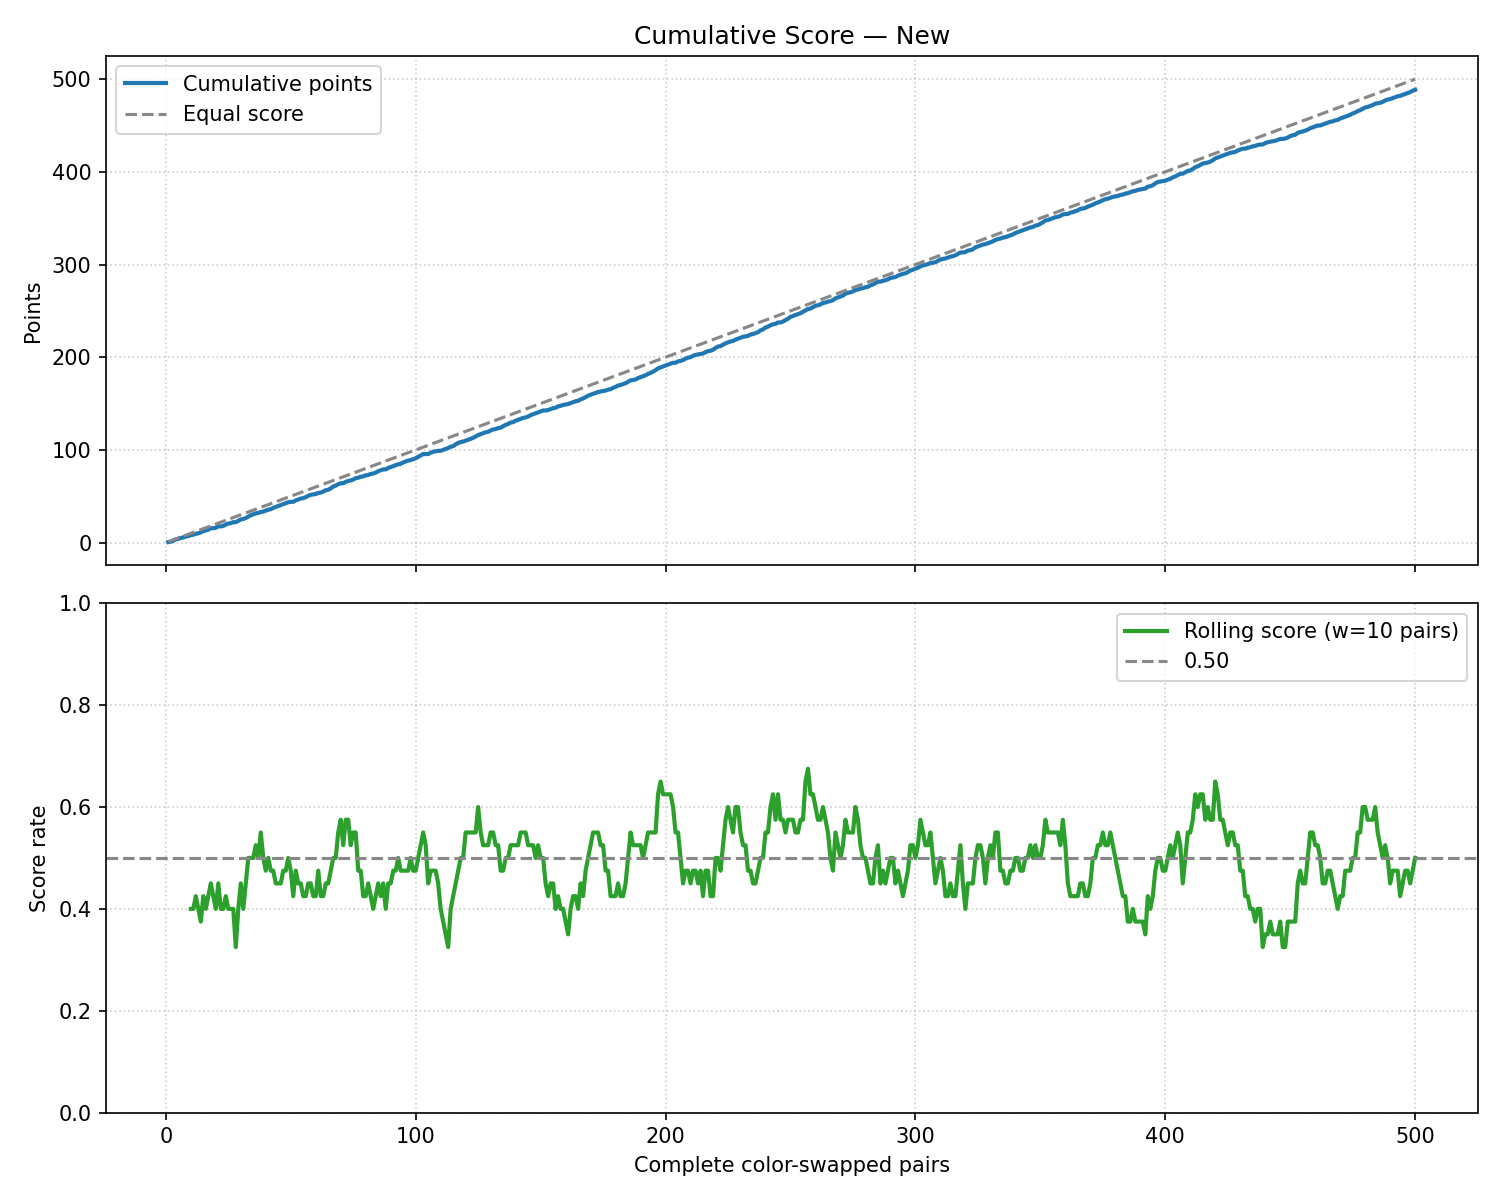


📈 Elo 置信區間收斂圖 (Elo CI)：


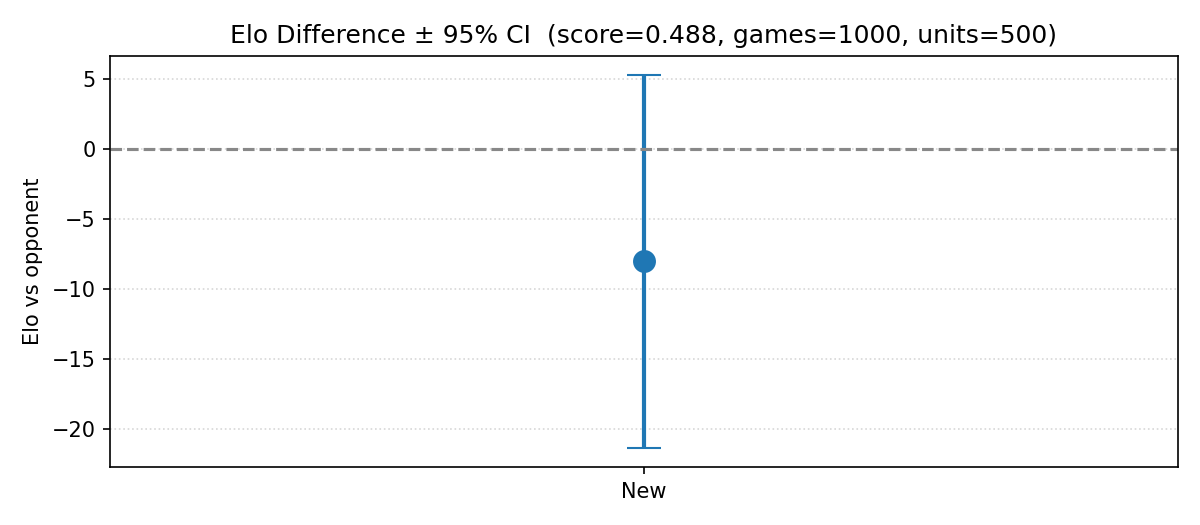


📈 每手搜尋深度 (Depth per Move)：


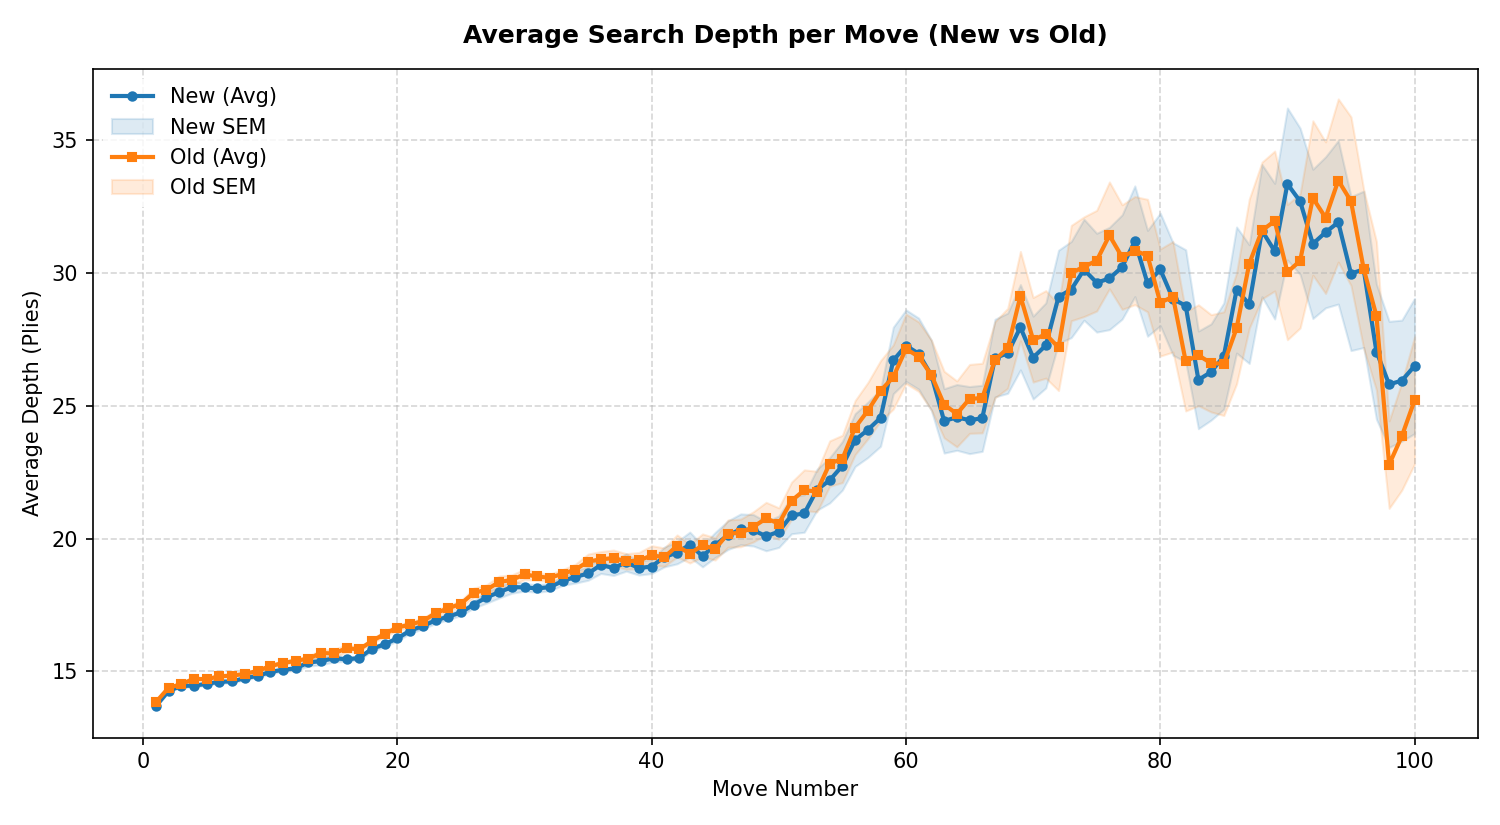


📈 同深度節點比例分佈 (Same-Depth Node Ratio)：


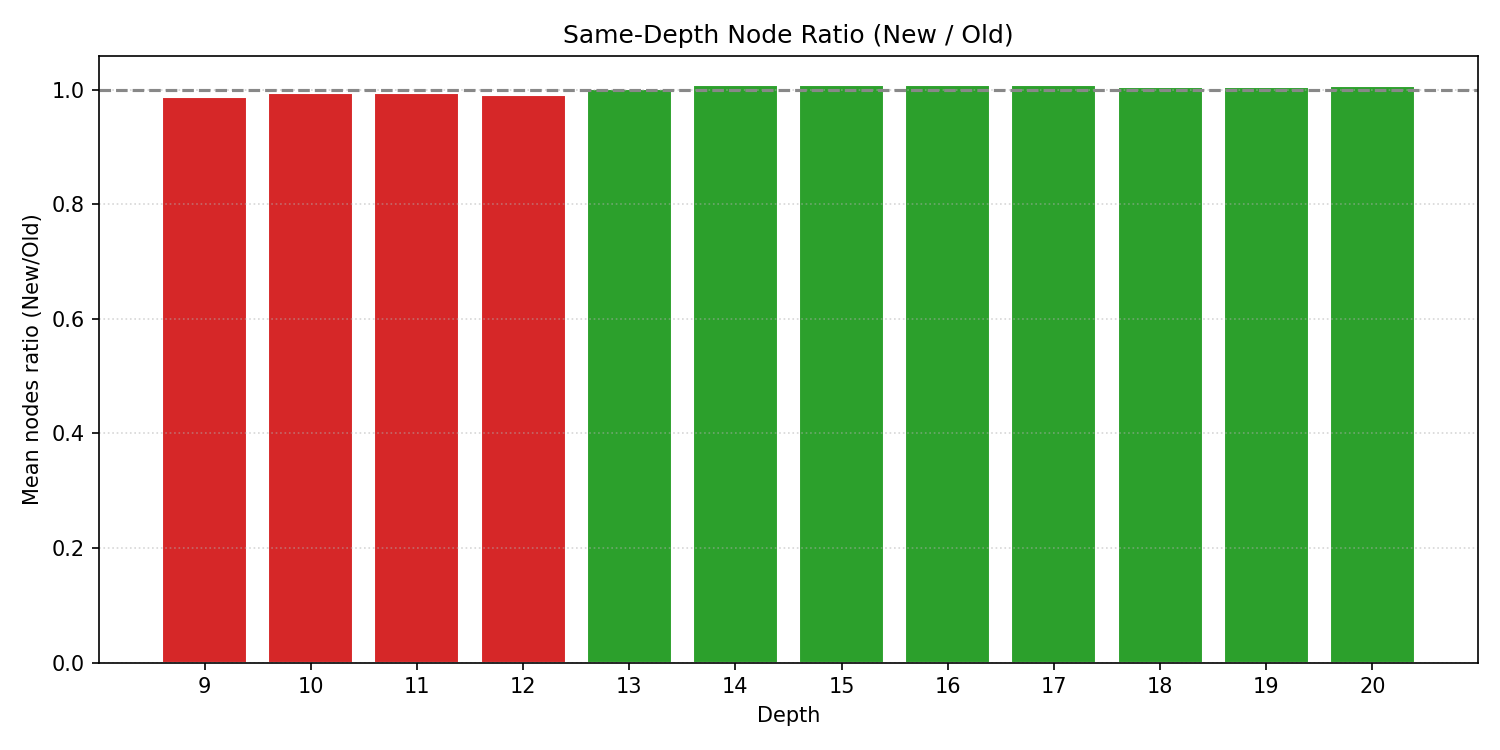


📈 平均節點數 vs 深度散佈 (Avg Nodes vs Depth)：


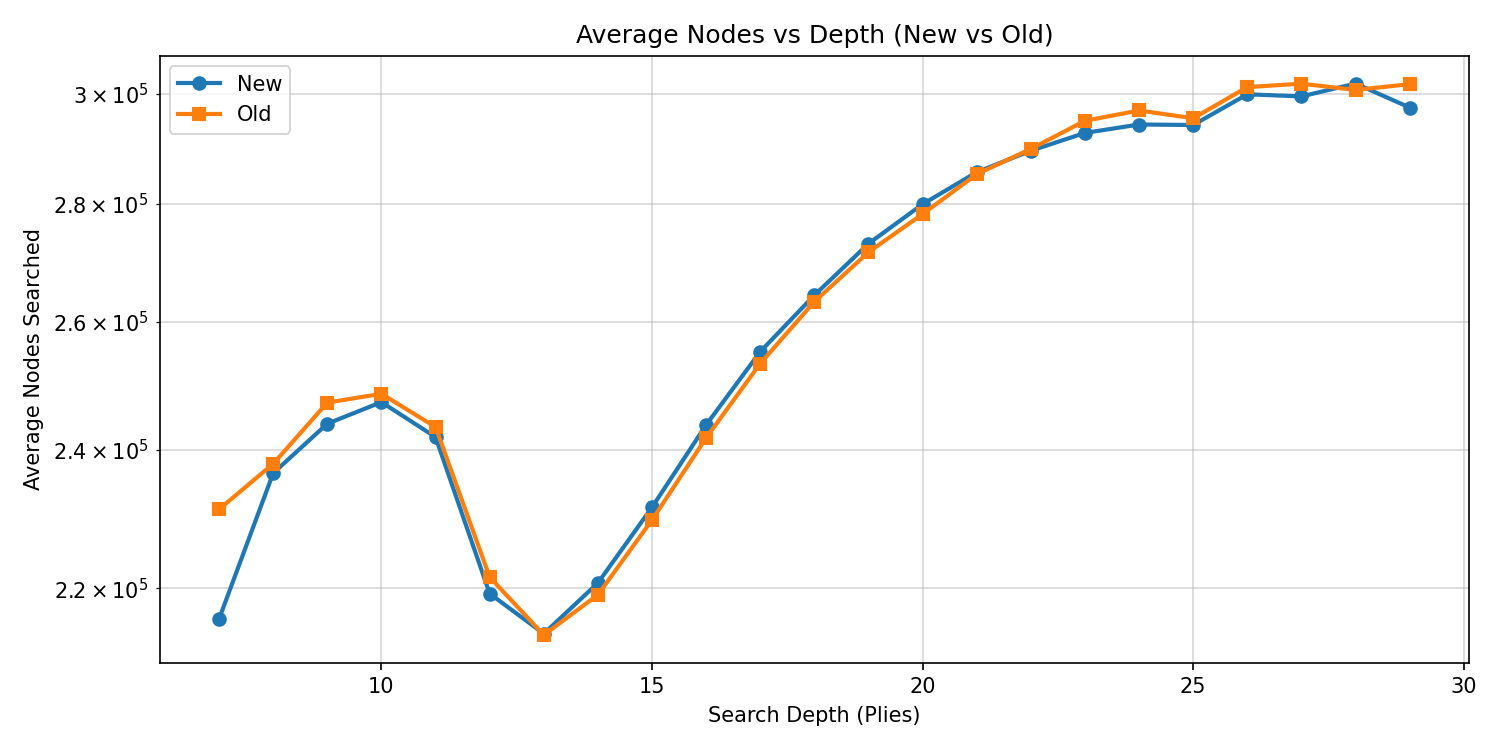


📈 黑白勝負分佈 (WDL by Color)：


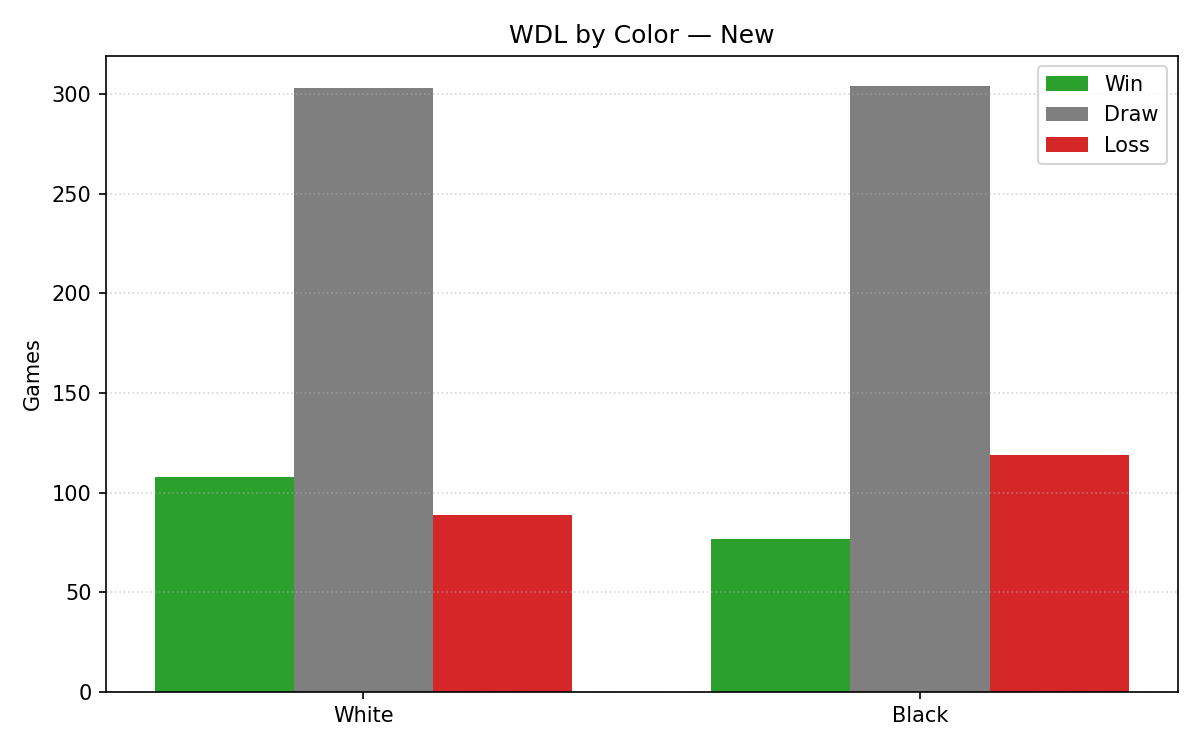

In [6]:
# =====================================================================
# 步驟 6: 視覺化關鍵圖表展示
# =====================================================================
import os
from IPython.display import Image, display

charts = [
    ("累積分數曲線 (Cumulative Score)", "tournament_analysis/cumulative_score.png"),
    ("Elo 置信區間收斂圖 (Elo CI)", "tournament_analysis/elo_ci.png"),
    ("每手搜尋深度 (Depth per Move)", "tournament_analysis/depth_per_move.png"),
    ("同深度節點比例分佈 (Same-Depth Node Ratio)", "tournament_analysis/same_depth_node_ratio.png"),
    ("平均節點數 vs 深度散佈 (Avg Nodes vs Depth)", "tournament_analysis/avg_nodes_vs_depth.png"),
    ("黑白勝負分佈 (WDL by Color)", "tournament_analysis/wdl_by_color.png"),
]

for title, path in charts:
    if os.path.exists(path):
        print(f"\n📈 {title}：")
        display(Image(filename=path))


In [ ]:
# =====================================================================
# 步驟 7: 一鍵打包所有報告、圖表與 PGN 棋譜並下載
# =====================================================================
import datetime

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
zip_filename = f"tournament_results_{timestamp}.zip"

!zip -q {zip_filename} tournament_analysis/*.png tournament_analysis/*.txt tournament_analysis/tournament_results.pgn
print(f"📦 已打包完成: {zip_filename}")

try:
    from google.colab import files
    files.download(zip_filename)
    print("⬇️ 已觸發下載！")
except ImportError:
    print(f"💡 本地環境執行，壓縮包位於當前目錄: {zip_filename}")


In [ ]:
from google.colab import runtime

# 執行這行會直接中斷並釋放目前使用的虛擬機器運算資源
runtime.unassign()
